dataset
↓
train / validation / test
↓
analisi timestamp
↓
finestre temporali
↓
32 eventName
↓
X_train / X_validation / X_test
↓
frequenze relative
↓
label SUS/EVIL
↓
PCA esplorativa

nelle prossime celle useremo:

pandas → lettura e manipolazione dei log BETH;

1. pandas → lettura e manipolazione dei log BETH;
2. numpy → operazioni numeriche;
3. matplotlib / seaborn → esplorazione e grafici;
4. Path → gestione ordinata dei file.




In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

print("Ambiente pronto!")

Ambiente pronto!


Subito dopo dobbiamo recuperare il dataset BETH e verificare la sua struttura. Prima lo carichiamo e facciamo:
file disponibili-> dimensioni-> nomi delle colonne -> prime righe-> tipi delle variabili-> valori mancanti-> distribuzione SUS / EVIL

In [ ]:
from google.colab import files

uploaded = files.upload()


Saving archive.zip to archive (1).zip


In [ ]:
import os

print("File caricati:")
for file in uploaded.keys():
    print("-", file)

File caricati:
- archive (1).zip


In [ ]:
import zipfile


zip_path = "archive.zip"
extract_path = "beth_data"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Contenuto del dataset:")
for root, dirs, files in os.walk(extract_path):
    for file in files:
        print(os.path.join(root, file))

Contenuto del dataset:
beth_data/labelled_2021may-ubuntu.csv
beth_data/labelled_2021may-ubuntu-dns.csv
beth_data/labelled_testing_data.csv
beth_data/labelled_2021may-ip-10-100-1-105.csv
beth_data/labelled_2021may-ip-10-100-1-105-dns.csv
beth_data/labelled_2021may-ip-10-100-1-4.csv
beth_data/labelled_2021may-ip-10-100-1-26.csv
beth_data/labelled_2021may-ip-10-100-1-95-dns.csv
beth_data/labelled_training_data.csv
beth_data/labelled_2021may-ip-10-100-1-186.csv
beth_data/labelled_validation_data.csv
beth_data/labelled_2021may-ip-10-100-1-26-dns.csv
beth_data/labelled_2021may-ip-10-100-1-95.csv
beth_data/labelled_2021may-ip-10-100-1-186-dns.csv
beth_data/labelled_2021may-ip-10-100-1-4-dns.csv




*   labelled_training_data.csv
*   labelled_validation_data.csv
*   labelled_testing_data.csv

Questi sono esattamente i tre file che ci interessano per partire con il benchmark.In più ci sono i log dei singoli host e i corrispondenti file DNS.
Prima leggiamo solo labelled_training_data.csv e vediamo esattamente cosa contiene.

In [ ]:
train_path = "beth_data/labelled_training_data.csv"

train_df = pd.read_csv(train_path)

print("Dimensioni:", train_df.shape)
print("\nColonne:")
print(train_df.columns.tolist())

Dimensioni: (763144, 16)

Colonne:
['timestamp', 'processId', 'threadId', 'parentProcessId', 'userId', 'mountNamespace', 'processName', 'hostName', 'eventId', 'eventName', 'stackAddresses', 'argsNum', 'returnValue', 'args', 'sus', 'evil']


In [ ]:
train_df.head()
train_df.info()
train_df[["sus", "evil"]].value_counts()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 763144 entries, 0 to 763143
Data columns (total 16 columns):
 #   Column           Non-Null Count   Dtype  
---  ------           --------------   -----  
 0   timestamp        763144 non-null  float64
 1   processId        763144 non-null  int64  
 2   threadId         763144 non-null  int64  
 3   parentProcessId  763144 non-null  int64  
 4   userId           763144 non-null  int64  
 5   mountNamespace   763144 non-null  int64  
 6   processName      763144 non-null  object 
 7   hostName         763144 non-null  object 
 8   eventId          763144 non-null  int64  
 9   eventName        763144 non-null  object 
 10  stackAddresses   763144 non-null  object 
 11  argsNum          763144 non-null  int64  
 12  returnValue      763144 non-null  int64  
 13  args             763144 non-null  object 
 14  sus              763144 non-null  int64  
 15  evil             763144 non-null  int64  
dtypes: float64(1), int64(10), object(5)
me

,,count
sus,evil,
0,0,761875
1,0,1269


* head() → come sono fatti concretamente gli eventi;
* info() → tipo delle colonne e presenza di valori mancanti;
* value_counts() → quanto sono sbilanciate le nostre label.

**Il training set è corretto**

Abbiamo:

763.144 righe × 16 colonne

Esattamente il numero di eventi riportato dal paper per il training set.

E tutte le 16 colonne sono valorizzate: non abbiamo valori mancanti nel training set.

Abbiamo:

* timestamp → tempo dell'evento
* processId, threadId, parentProcessId → informazioni sui processi
* userId → utente che genera l'evento
* mountNamespace → namespace
* processName → nome del processo
* hostName → host
* eventId, eventName → tipo di evento
* stackAddresses, args → informazioni più complesse
* argsNum, returnValue
* sus, evil → label

Il training non contiene eventi EVIL, ma contiene una piccola componente di eventi SUS.

* 761.875 eventi normali
* 1.269 eventi sus
* 0 eventi evil


Dobbiamo capire:

quanto durano gli eventi nel training e quali eventName sono presenti.
Questa cella ci serve per rispondere a tre domande:

* Quanti tipi diversi di eventi/syscall abbiamo?
* Quali sono gli eventi più frequenti?
* Quanto è lungo il periodo temporale coperto dal training?

In [ ]:
print("Numero di eventName distinti:", train_df["eventName"].nunique())

print("\nPrimi eventName:")
print(train_df["eventName"].value_counts().head(20))

print("\nIntervallo temporale:")
print("Min:", train_df["timestamp"].min())
print("Max:", train_df["timestamp"].max())
print("Durata:", train_df["timestamp"].max() - train_df["timestamp"].min(), "secondi")

Numero di eventName distinti: 32

Primi eventName:
eventName
close                 218080
openat                209730
security_file_open    148611
fstat                  80071
stat                   41931
access                 14383
cap_capable             9825
lstat                   7031
getdents64              6149
socket                  5971
connect                 3581
kill                    2818
dup2                    2389
getsockname             2308
unlink                  1809
sched_process_exit      1409
prctl                   1379
clone                   1299
bind                     853
accept4                  772
Name: count, dtype: int64

Intervallo temporale:
Min: 132.560721
Max: 3954.587643
Durata: 3822.026922 secondi


Abbiamo 32 eventName distinti. Quindi la nostra matrice di frequenza non sarà enorme: avremo, in prima approssimazione, 32 feature, una per ogni tipo di evento.

Il training copre una duratcira di circa 3822 secondi, cioè 63,7 minuti.

Quindi abbiamo circa un'ora di attività osservata.

Prima di scegliere la dimensione della finestra, voglio vedere come gli eventi sono distribuiti nel tempo.

Facciamo un primo grafico molto semplice: dividiamo il training in finestre da 60 secondi, ma solo per visualizzare la distribuzione. Non stiamo ancora decidendo che 60 secondi sarà la finestra della tesi.

In [ ]:
# Creiamo una copia per non modificare il dataset originale
train_temp = train_df.copy()

# Tempo relativo all'inizio del dataset
train_temp["time_relative"] = (
    train_temp["timestamp"] - train_temp["timestamp"].min()
)

# Finestra temporale di 60 secondi
train_temp["window_60s"] = (
    train_temp["time_relative"] // 60
).astype(int)

# Numero di eventi per finestra
events_per_window = train_temp.groupby("window_60s").size()

print("Numero di finestre:", len(events_per_window))
print("\nPrime 10 finestre:")
print(events_per_window.head(10))

Numero di finestre: 64

Prime 10 finestre:
window_60s
0    49938
1     6204
2     8939
3     8887
4    32688
5    13854
6     8726
7     8644
8     9145
9    10866
dtype: int64


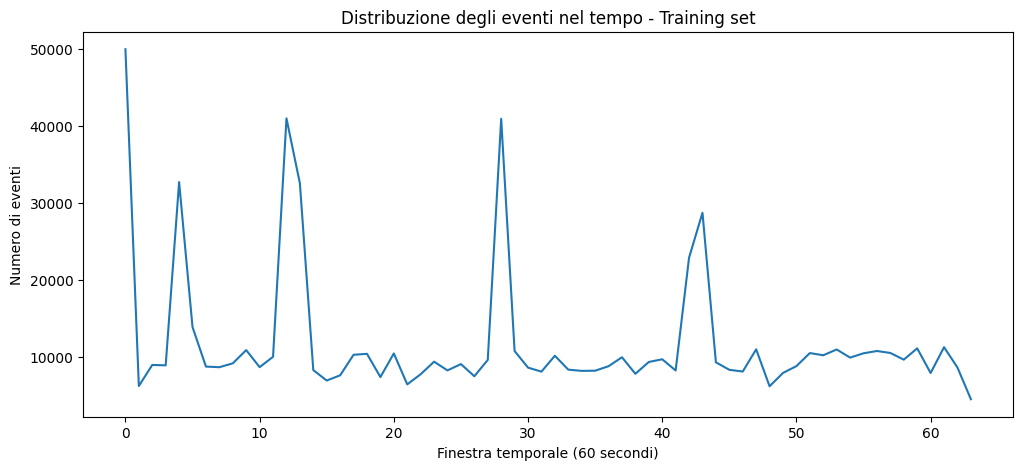

In [ ]:
plt.figure(figsize=(12, 5))

plt.plot(
    events_per_window.index,
    events_per_window.values
)

plt.xlabel("Finestra temporale (60 secondi)")
plt.ylabel("Numero di eventi")
plt.title("Distribuzione degli eventi nel tempo - Training set")

plt.show()

il training non ha un'attività temporale uniforme e dal grafico vediamo diversi picchi molto marcati.

Però attenzione a una cosa

Questi picchi non sono automaticamente anomalie. Quindi non possiamo ancora dire che i picchi corrispondano ad attacchi — e nel training sappiamo addirittura che non ci sono eventi evil.

Prendiamo la finestra 0, quella con ~50.000 eventi, e vediamo da quali eventName è composta.

In [ ]:
window_0 = train_temp[train_temp["window_60s"] == 0]

print("Eventi nella finestra 0:", len(window_0))
print("\nDistribuzione degli eventName:")
print(window_0["eventName"].value_counts())

Eventi nella finestra 0: 49938

Distribuzione degli eventName:
eventName
close                    14206
openat                   14145
fstat                     9063
security_file_open        3637
access                    2964
cap_capable               1613
lstat                     1397
stat                       927
getdents64                 442
unlink                     388
prctl                      256
socket                     140
kill                       113
security_inode_unlink       89
sched_process_exit          84
getsockname                 82
unlinkat                    80
clone                       70
connect                     66
bind                        61
dup2                        40
accept4                     18
execve                      12
security_bprm_check         12
dup3                         8
fchmod                       6
dup                          6
umount                       4
accept                       3
setgid                      

Poi facciamo la stessa cosa per una finestra molto più tranquilla, per esempio la finestra 1:

In [ ]:
window_1 = train_temp[train_temp["window_60s"] == 1]

print("Eventi nella finestra 1:", len(window_1))
print("\nDistribuzione degli eventName:")
print(window_1["eventName"].value_counts())

Eventi nella finestra 1: 6204

Distribuzione degli eventName:
eventName
close                  1798
openat                 1773
security_file_open     1743
stat                    528
fstat                   238
socket                   25
dup2                     22
getdents64               14
cap_capable              10
clone                     7
access                    7
getsockname               7
execve                    6
security_bprm_check       6
connect                   6
sched_process_exit        5
dup                       2
prctl                     2
accept                    1
bind                      1
lstat                     1
setgid                    1
setuid                    1
Name: count, dtype: int64


Alla fine vogliamo costruire una tabella in cui:
* Ogni riga rappresenta una finestra temporale.

* Ogni colonna rappresenta un tipo di evento.

Il numero dentro la cella indica quante volte quell'evento è comparso nella finestra.

Una volta costruita la tabella, possiamo dire al modello:

"Queste sono le caratteristiche delle finestre che considero normali. Impara a riconoscerle."

Poi gli diamo le finestre di test e il modello assegna a ciascuna un anomaly score.

In [ ]:
# Intervallo temporale tra eventi consecutivi
time_diff = train_df["timestamp"].diff().dropna()

print("Statistiche degli intervalli tra eventi:")
print(time_diff.describe())
print("\nPercentili degli intervalli temporali (secondi):")
print(time_diff.quantile([0.50, 0.75, 0.90, 0.95, 0.99, 0.999]))

Statistiche degli intervalli tra eventi:
count    763143.000000
mean         -0.001946
std          17.386162
min       -3819.566762
25%           0.000048
50%           0.000082
75%           0.000174
max        2964.706158
Name: timestamp, dtype: float64

Percentili degli intervalli temporali (secondi):
0.500     0.000082
0.750     0.000174
0.900     0.000388
0.950     0.001028
0.990     0.083038
0.999    17.715733
Name: timestamp, dtype: float64


In [ ]:
is_sorted = train_df["timestamp"].is_monotonic_increasing

print("Timestamp ordinati:", is_sorted)

Timestamp ordinati: False


l'ordine delle righe del CSV non coincide con l'ordine cronologico globale degli eventi.
Dobbiamo lavorare con gli eventi in ordine cronologico.

Però non modifichiamo train_df direttamente. Creiamo una nuova copia, così conserviamo anche il dataset originale.

In [ ]:
train_sorted = train_df.sort_values("timestamp").reset_index(drop=True)

print("Timestamp ordinati:", train_sorted["timestamp"].is_monotonic_increasing)

Timestamp ordinati: True


In [ ]:
time_diff_sorted = train_sorted["timestamp"].diff().dropna()

print(time_diff_sorted.describe())
print("\nPercentili:")
print(
    time_diff_sorted.quantile(
        [0.50, 0.75, 0.90, 0.95, 0.99, 0.999]
    )
)


count    763143.000000
mean          0.005008
std           0.141368
min           0.000000
25%           0.000048
50%           0.000075
75%           0.000154
max          19.301985
Name: timestamp, dtype: float64

Percentili:
0.500    0.000075
0.750    0.000154
0.900    0.000217
0.950    0.000601
0.990    0.003152
0.999    1.474443
Name: timestamp, dtype: float64


Quanto comportamento vogliamo riassumere in una singola osservazione che daremo al modello?
Costruiamo una prima matrice con 60 secondi, proprio come prototipo. Se funziona e ha senso, successivamente potremo confrontare altre dimensioni.

In [ ]:
# Durata della finestra in secondi
WINDOW_SIZE = 60

train_windowed = train_sorted.copy()

# Tempo relativo all'inizio del dataset
train_windowed["time_relative"] = (
    train_windowed["timestamp"] - train_windowed["timestamp"].min()
)

# Numero della finestra temporale
train_windowed["window"] = (
    train_windowed["time_relative"] // WINDOW_SIZE
).astype(int)

print("Numero di finestre:", train_windowed["window"].nunique())
print("\nEventi per finestra:")
print(train_windowed["window"].value_counts().sort_index().head(10))

Numero di finestre: 64

Eventi per finestra:
window
0    49938
1     6204
2     8939
3     8887
4    32688
5    13854
6     8726
7     8644
8     9145
9    10866
Name: count, dtype: int64


Poi trasformiamo gli eventi in frequenze

In [ ]:
X_train = pd.crosstab(
    train_windowed["window"],
    train_windowed["eventName"]
)

print("Dimensioni della matrice X:", X_train.shape)

X_train.head()

Dimensioni della matrice X: (64, 32)


eventName,accept,accept4,access,bind,cap_capable,clone,close,connect,dup,dup2,...,security_file_open,security_inode_unlink,setgid,setuid,socket,stat,symlink,umount,unlink,unlinkat
window,,,,,,,,,,,,,,,,,,,,,
0,3,18,2964,61,1613,70,14206,66,6,40,...,3637,89,3,3,140,927,0,4,388,80
1,1,0,7,1,10,7,1798,6,2,22,...,1743,0,1,1,25,528,0,0,0,0
2,1,7,10,7,34,23,2571,24,2,28,...,2458,0,1,1,43,728,0,0,0,0
3,0,0,7,0,2,11,2518,56,0,21,...,2414,0,0,0,89,817,0,0,0,0
4,0,0,2087,100,455,107,9763,0,0,21,...,3166,24,0,0,128,932,0,0,284,0


Questa tabella è la matrice di frequenza

Il prossimo passaggio sarà confrontare conteggi assoluti e frequenze relative.

In [ ]:
print("WINDOW 0 - frequenze relative")
print((X_train.loc[0] / X_train.loc[0].sum()).sort_values(ascending=False))
print("WINDOW 1 - frequenze relative")
print((X_train.loc[1] / X_train.loc[1].sum()).sort_values(ascending=False))

WINDOW 0 - frequenze relative
eventName
close                    0.284473
openat                   0.283251
fstat                    0.181485
security_file_open       0.072830
access                   0.059354
cap_capable              0.032300
lstat                    0.027975
stat                     0.018563
getdents64               0.008851
unlink                   0.007770
prctl                    0.005126
socket                   0.002803
kill                     0.002263
security_inode_unlink    0.001782
sched_process_exit       0.001682
getsockname              0.001642
unlinkat                 0.001602
clone                    0.001402
connect                  0.001322
bind                     0.001222
dup2                     0.000801
accept4                  0.000360
execve                   0.000240
security_bprm_check      0.000240
dup3                     0.000160
dup                      0.000120
fchmod                   0.000120
umount                   0.000080
accept  

Con finestre di 60s abbiamo ottenuto solo 64 osservazioni il che è pochissimo per fare anomaly detection seriamente.
Se invece considerassimo finestre di 10 secondi avremmo 382 finestre per 32 feature.
Ma c'è un compromesso:

* finestre troppo grandi → poche osservazioni e anomalie molto "diluite";
* finestre troppo piccole → poche informazioni per finestra e maggiore variabilità.

In [ ]:
window_sizes = [5, 10, 30, 60, 120]

print("Dimensione finestra | Numero finestre")
print("-" * 40)

for size in window_sizes:
    n_windows = int(
        np.ceil(
            (train_sorted["timestamp"].max() - train_sorted["timestamp"].min())
            / size
        )
    )

    print(f"{size:>18} s | {n_windows}")

Dimensione finestra | Numero finestre
----------------------------------------
                 5 s | 765
                10 s | 383
                30 s | 128
                60 s | 64
               120 s | 32


Voglio sapere quanti eventi contiene ciascuna finestra per le diverse granularità.

Questo ci permette di capire se con 5 secondi alcune finestre diventano quasi vuote, mentre con 120 secondi accumuliamo troppi eventi.

In [ ]:
window_sizes = [5, 10, 30, 60, 120]

for size in window_sizes:
    temp = train_sorted.copy()

    temp["window"] = (
        (temp["timestamp"] - temp["timestamp"].min()) // size
    ).astype(int)

    events_per_window = temp.groupby("window").size()

    print(f"\n===== FINESTRA {size} secondi =====")
    print(f"Numero finestre: {len(events_per_window)}")
    print(f"Eventi minimi:   {events_per_window.min()}")
    print(f"Eventi massimi:  {events_per_window.max()}")
    print(f"Eventi medi:     {events_per_window.mean():.2f}")
    print(f"Mediana:         {events_per_window.median():.2f}")
    print(f"Finestre con 0 eventi: {(events_per_window == 0).sum()}")


===== FINESTRA 5 secondi =====
Numero finestre: 688
Eventi minimi:   1
Eventi massimi:  32295
Eventi medi:     1109.22
Mediana:         91.00
Finestre con 0 eventi: 0

===== FINESTRA 10 secondi =====
Numero finestre: 376
Eventi minimi:   1
Eventi massimi:  35439
Eventi medi:     2029.64
Mediana:         539.50
Finestre con 0 eventi: 0

===== FINESTRA 30 secondi =====
Numero finestre: 128
Eventi minimi:   76
Eventi massimi:  48716
Eventi medi:     5962.06
Mediana:         5497.00
Finestre con 0 eventi: 0

===== FINESTRA 60 secondi =====
Numero finestre: 64
Eventi minimi:   4487
Eventi massimi:  49938
Eventi medi:     11924.12
Mediana:         9212.00
Finestre con 0 eventi: 0

===== FINESTRA 120 secondi =====
Numero finestre: 32
Eventi minimi:   13093
Eventi massimi:  73488
Eventi medi:     23848.25
Mediana:         18176.50
Finestre con 0 eventi: 0


Creiamo un grafico per 30 secondi, perché è il compromesso che al momento sembra più interessante.

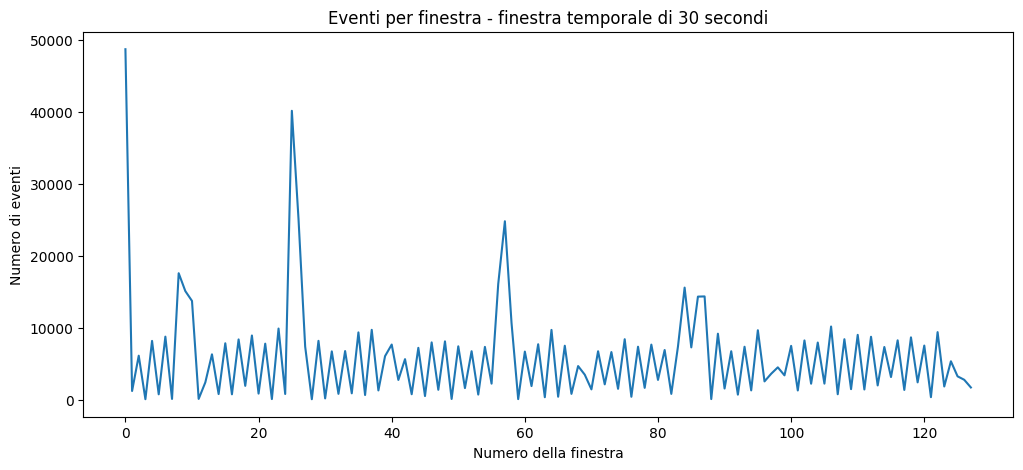

In [ ]:
WINDOW_SIZE = 30

temp = train_sorted.copy()

temp["window"] = (
    (temp["timestamp"] - temp["timestamp"].min()) // WINDOW_SIZE
).astype(int)

events_per_window = temp.groupby("window").size()

plt.figure(figsize=(12, 5))
plt.plot(events_per_window.index, events_per_window.values)

plt.xlabel("Numero della finestra")
plt.ylabel("Numero di eventi")
plt.title("Eventi per finestra - finestra temporale di 30 secondi")

plt.show()

anche con finestre da 30 secondi l'attività non è uniforme. Ci sono alcuni picchi molto grandi e molti intervalli con attività più bassa.

Siamo ancora nel training, e dal dataset sappiamo che il training contiene 761.875 eventi normali e 1.269 sus, ma nessun evil.

Quindi un picco può tranquillamente essere comportamento normale.

**Adesso affrontiamo le LABEL**
ogni finestra → è normale o contiene attività sospetta?
Il problema è che BETH assegna sus ed evil ai singoli eventi, non alle finestre.
Usiamo train_sorted, che abbiamo già creato, e guardiamo in quali finestre da 30 secondi cadono gli eventi sus. Poi facciamo la stessa cosa per evil.

In [ ]:
# Creiamo le finestre da 30 secondi
train_label_check = train_sorted.copy()

train_label_check["window"] = (
    (train_label_check["timestamp"] - train_label_check["timestamp"].min()) // 30
).astype(int)

# Quante label sus ci sono in ogni finestra?
sus_per_window = (
    train_label_check
    .groupby("window")["sus"]
    .sum()
)

print("Finestre che contengono almeno un evento SUS:")
print(sus_per_window[sus_per_window > 0])

Finestre che contengono almeno un evento SUS:
window
0      996
18      33
40      66
55      18
56      99
58      33
115     19
116      5
Name: sus, dtype: int64


In [ ]:
evil_per_window = (
    train_label_check
    .groupby("window")["evil"]
    .sum()
)

print("Finestre che contengono almeno un evento EVIL:")
print(evil_per_window[evil_per_window > 0])

Finestre che contengono almeno un evento EVIL:
Series([], Name: evil, dtype: int64)


La finestra 0 contiene 996 dei 1.269 eventi sus.

Quindi circa:

78,5% degli eventi sus del training si trovano nella prima finestra da 30 secondi.

Finora abbiamo guardato soltanto il training.

Carichiamo gli altri due dataset:

In [ ]:
validation_df = pd.read_csv(
    "beth_data/labelled_validation_data.csv"
)

test_df = pd.read_csv(
    "beth_data/labelled_testing_data.csv"
)

print("TRAIN:", train_df.shape)
print("VALIDATION:", validation_df.shape)
print("TEST:", test_df.shape)

TRAIN: (763144, 16)
VALIDATION: (188967, 16)
TEST: (188967, 16)


In [ ]:
print("TRAIN")
print(train_df[["sus", "evil"]].value_counts())

print("\nVALIDATION")
print(validation_df[["sus", "evil"]].value_counts())

print("\nTEST")
print(test_df[["sus", "evil"]].value_counts())

TRAIN
sus  evil
0    0       761875
1    0         1269
Name: count, dtype: int64

VALIDATION
sus  evil
0    0       188181
1    0          786
Name: count, dtype: int64

TEST
sus  evil
1    1       158432
0    0        17508
1    0        13027
Name: count, dtype: int64


I tre split sono molto diversi. In Training e Validation è praticamente tutto normale. Nel Test succede qualcosa di completamente diverso perché è fortemente orientato verso gli eventi evil. Non dobbiamo trattare training, validation e test allo stesso modo.

Ogni dataset deve essere trasformato in finestre in modo coerente, ma dobbiamo capire se i timestamp dei tre file rappresentano una timeline comune o dataset separati. Inoltre, voglio vedere quanti eventName diversi ci sono in ciascuno split. Questo è importante perché abbiamo costruito le nostre feature sulla base dei 32 eventi presenti nel training.

In [ ]:
for name, df in [
    ("TRAIN", train_df),
    ("VALIDATION", validation_df),
    ("TEST", test_df)
]:
    print(f"\n{name}")
    print("Min timestamp:", df["timestamp"].min())
    print("Max timestamp:", df["timestamp"].max())
    print("Durata:", df["timestamp"].max() - df["timestamp"].min())


TRAIN
Min timestamp: 132.560721
Max timestamp: 3954.587643
Durata: 3822.026922

VALIDATION
Min timestamp: 124.439221
Max timestamp: 778.146811
Durata: 653.70759

TEST
Min timestamp: 129.050634
Max timestamp: 496.629091
Durata: 367.578457


In [ ]:
for name, df in [
    ("TRAIN", train_df),
    ("VALIDATION", validation_df),
    ("TEST", test_df)
]:
    print(
        f"{name}: {df['eventName'].nunique()} eventName distinti"
    )

TRAIN: 32 eventName distinti
VALIDATION: 29 eventName distinti
TEST: 46 eventName distinti


 train, validation e test sono tre registrazioni temporali separate, non tre pezzi consecutivi della stessa timeline. Quindi non dobbiamo costruire le finestre usando i timestamp del training per poi applicarle a validation/test. Ogni split va suddiviso autonomamente in finestre di 30 secondi, partendo dal proprio timestamp minimo.

Gli eventi che compaiono solo in validation/test non vengono trasformati in nuove colonne.

Per la nostra matrice di feature basata sugli eventName del training, semplicemente non contribuiscono alle 32 feature.

Creiamo una funzione che faccia automaticamente:

* ordinamento temporale;
* creazione delle finestre;
* conteggio degli eventName;
* allineamento alle feature del training.
Prima definiamo le feature del training

In [ ]:
event_features = sorted(train_df["eventName"].unique())

print("Numero di feature:", len(event_features))
print("\nFeature:")
print(event_features)

Numero di feature: 32

Feature:
['accept', 'accept4', 'access', 'bind', 'cap_capable', 'clone', 'close', 'connect', 'dup', 'dup2', 'dup3', 'execve', 'fchmod', 'fstat', 'getdents64', 'getsockname', 'kill', 'lstat', 'openat', 'prctl', 'sched_process_exit', 'security_bprm_check', 'security_file_open', 'security_inode_unlink', 'setgid', 'setuid', 'socket', 'stat', 'symlink', 'umount', 'unlink', 'unlinkat']


In [ ]:
def create_window_features(df, event_features, window_size=30):

    # Copia del dataset
    data = df.copy()

    # Ordinamento temporale
    data = data.sort_values("timestamp").reset_index(drop=True)

    # Tempo relativo all'inizio del dataset
    data["time_relative"] = (
        data["timestamp"] - data["timestamp"].min()
    )

    # Numero della finestra
    data["window"] = (
        data["time_relative"] // window_size
    ).astype(int)

    # Conteggio degli eventName per finestra
    X = pd.crosstab(
        data["window"],
        data["eventName"]
    )

    # Manteniamo ESATTAMENTE le feature del training
    X = X.reindex(
        columns=event_features,
        fill_value=0
    )

    return X

Ora applichiamola ai tre dataset

In [ ]:
X_train = create_window_features(
    train_df,
    event_features,
    window_size=30
)

X_validation = create_window_features(
    validation_df,
    event_features,
    window_size=30
)

X_test = create_window_features(
    test_df,
    event_features,
    window_size=30
)

In [ ]:
print("X_train:", X_train.shape)
print("X_validation:", X_validation.shape)
print("X_test:", X_test.shape)

X_train: (128, 32)
X_validation: (22, 32)
X_test: (13, 32)


In [ ]:
print(
    "Colonne identiche:",
    list(X_train.columns) ==
    list(X_validation.columns) ==
    list(X_test.columns)
)

Colonne identiche: True


Abbiamo definito le 32 feature a partire esclusivamente dal training e poi abbiamo trasformato i tre dataset usando sempre quelle stesse 32 colonne.

Ma abbiamo ancora le label a livello di evento. Dobbiamo trasformarle in label a livello di finestra.

Vediamo cosa c'è dentro ogni finestra

In [ ]:
def create_window_labels(df, window_size=30):

    data = df.copy()

    # Ordine temporale
    data = data.sort_values("timestamp").reset_index(drop=True)

    # Tempo relativo
    data["time_relative"] = (
        data["timestamp"] - data["timestamp"].min()
    )

    # Numero finestra
    data["window"] = (
        data["time_relative"] // window_size
    ).astype(int)

    # Statistiche per finestra
    labels = data.groupby("window").agg(
        n_events=("eventName", "size"),
        sus=("sus", "sum"),
        evil=("evil", "sum")
    )

    return labels

Ora applichiamola ai tre dataset

In [ ]:
labels_train = create_window_labels(train_df, 30)
labels_validation = create_window_labels(validation_df, 30)
labels_test = create_window_labels(test_df, 30)
print("TRAIN")
print(labels_train)

print("\nVALIDATION")
print(labels_validation)

print("\nTEST")
print(labels_test)

TRAIN
        n_events  sus  evil
window                     
0          48716  996     0
1           1222    0     0
2           6124    0     0
3             80    0     0
4           8180    0     0
...          ...  ...   ...
123         1843    0     0
124         5349    0     0
125         3257    0     0
126         2778    0     0
127         1709    0     0

[128 rows x 3 columns]

VALIDATION
        n_events  sus  evil
window                     
0          79220  777     0
1           2765    0     0
2           2308    0     0
3           1182    0     0
4           2401    0     0
5           1204    0     0
6            298    0     0
7           3485    0     0
8             72    0     0
9          29512    0     0
10           327    0     0
11          4173    0     0
12            60    0     0
13         16181    0     0
14         10559    0     0
15          3346    0     0
16           246    0     0
17         17604    0     0
18          7103    0     0
19    

In [ ]:
print("TRAIN - finestre con SUS o EVIL")
print(
    labels_train[
        (labels_train["sus"] > 0) |
        (labels_train["evil"] > 0)
    ]
)

print("\nVALIDATION - finestre con SUS o EVIL")
print(
    labels_validation[
        (labels_validation["sus"] > 0) |
        (labels_validation["evil"] > 0)
    ]
)

print("\nTEST - finestre con SUS o EVIL")
print(
    labels_test[
        (labels_test["sus"] > 0) |
        (labels_test["evil"] > 0)
    ]
)

TRAIN - finestre con SUS o EVIL
        n_events  sus  evil
window                     
0          48716  996     0
18          1935   33     0
40          7674   66     0
55          2242   18     0
56         16090   99     0
58         10654   33     0
115         3157   19     0
116         8261    5     0

VALIDATION - finestre con SUS o EVIL
        n_events  sus  evil
window                     
0          79220  777     0
21          3487    9     0

TEST - finestre con SUS o EVIL
        n_events     sus    evil
window                          
0           4262     967      16
3            690     580       0
4           1234      12       0
9          25128   17445    6590
10          2925    2645    2016
11        126190  125020  125020
12         24790   24790   24790


Non dobbiamo creare una sola label perché perderemmo informazione.

È molto più utile conservare due informazioni separate

Nel test ci sono delle finestre enormissime rispetto ad altre quindi la distribuzione del numero di eventi è estremamente sbilanciata.

Questa potrebbe essere proprio una caratteristica interessante del dataset.

Ma significa che dobbiamo stare attenti a una cosa:

il modello potrebbe usare semplicemente il volume degli eventi come segnale di anomalia.

In [ ]:
X_train_rel = X_train.div(
    X_train.sum(axis=1),
    axis=0
)

X_validation_rel = X_validation.div(
    X_validation.sum(axis=1),
    axis=0
)

X_test_rel = X_test.div(
    X_test.sum(axis=1),
    axis=0
)

In [ ]:
print("Somma feature TRAIN:")
print(X_train_rel.sum(axis=1).head())

print("\nSomma feature VALIDATION:")
print(X_validation_rel.sum(axis=1).head())

print("\nSomma feature TEST:")
print(X_test_rel.sum(axis=1).head())

Somma feature TRAIN:
window
0    1.0
1    1.0
2    1.0
3    1.0
4    1.0
dtype: float64

Somma feature VALIDATION:
window
0    1.0
1    1.0
2    1.0
3    1.0
4    1.0
dtype: float64

Somma feature TEST:
window
0    1.0
1    1.0
2    1.0
3    1.0
4    1.0
dtype: float64


In [ ]:
print("WINDOW 0 - conteggi")
print(X_train.loc[0].sort_values(ascending=False).head(10))

print("\nWINDOW 0 - frequenze relative")
print(X_train_rel.loc[0].sort_values(ascending=False).head(10))

WINDOW 0 - conteggi
eventName
openat                13923
close                 13884
fstat                  8867
security_file_open     3437
access                 2960
cap_capable            1569
lstat                  1396
stat                    906
getdents64              410
unlink                  388
Name: 0, dtype: int64

WINDOW 0 - frequenze relative
eventName
openat                0.285799
close                 0.284999
fstat                 0.182014
security_file_open    0.070552
access                0.060760
cap_capable           0.032207
lstat                 0.028656
stat                  0.018598
getdents64            0.008416
unlink                0.007965
Name: 0, dtype: float64


Il prossimo passo: creare le label delle finestre.
X_train
X_validation
X_test

X_train_rel
X_validation_rel
X_test_rel.
Ora dobbiamo creare:

y_train_sus
y_validation_sus
y_test_sus

y_train_evil
y_validation_evil
y_test_evil

In [ ]:
y_train = create_window_labels(train_df, 30)
y_validation = create_window_labels(validation_df, 30)
y_test = create_window_labels(test_df, 30)

In [ ]:
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_validation:", X_validation.shape)
print("y_validation:", y_validation.shape)

print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

X_train: (128, 32)
y_train: (128, 3)
X_validation: (22, 32)
y_validation: (22, 3)
X_test: (13, 32)
y_test: (13, 3)


In [ ]:
for labels in [y_train, y_validation, y_test]:
    labels["sus_window"] = (labels["sus"] > 0).astype(int)
    labels["evil_window"] = (labels["evil"] > 0).astype(int)

In [ ]:
print("TRAIN")
print(y_train[y_train["sus_window"] == 1])

print("\nVALIDATION")
print(y_validation[y_validation["sus_window"] == 1])

print("\nTEST")
print(y_test[y_test["sus_window"] == 1])

TRAIN
        n_events  sus  evil  sus_window  evil_window
window                                              
0          48716  996     0           1            0
18          1935   33     0           1            0
40          7674   66     0           1            0
55          2242   18     0           1            0
56         16090   99     0           1            0
58         10654   33     0           1            0
115         3157   19     0           1            0
116         8261    5     0           1            0

VALIDATION
        n_events  sus  evil  sus_window  evil_window
window                                              
0          79220  777     0           1            0
21          3487    9     0           1            0

TEST
        n_events     sus    evil  sus_window  evil_window
window                                                   
0           4262     967      16           1            1
3            690     580       0           1            0
4 

In [ ]:
print("\nTEST - finestre EVIL")
print(y_test[y_test["evil_window"] == 1])


TEST - finestre EVIL
        n_events     sus    evil  sus_window  evil_window
window                                                   
0           4262     967      16           1            1
9          25128   17445    6590           1            1
10          2925    2645    2016           1            1
11        126190  125020  125020           1            1
12         24790   24790   24790           1            1


Le 32 feature utilizzate come input dei modelli rappresentano le **frequenze relative degli `eventName` all'interno di ciascuna finestra temporale di 30 secondi**.

I conteggi assoluti vengono prima calcolati per ogni finestra e successivamente normalizzati dividendo ciascuna feature per il numero totale di eventi della finestra.

In questo modo ogni finestra è rappresentata da un vettore di 32 frequenze relative, la cui somma è pari a 1.


sus_window e evil_window non entrano nel modello.

Serviranno dopo per verificare se le finestre che il modello considera anomale corrispondono effettivamente a SUS/EVIL.





  X = ciò che il modello vede
    
    
  y = ciò che usiamo per giudicare il modello

abbiamo due possibili X:
* Conteggi (X_train
X_validation
X_test)
* Frequenze relative (X_train_rel
X_validation_rel
X_test_rel)


possiamo verificare empiricamente se è meglio rappresentare una finestra attraverso il volume assoluto di eventi oppure attraverso la composizione relativa degli eventi.

Non dobbiamo scegliere a priori.


Nel training non abbiamo finestre EVIL.

Questo è coerente con l'idea di anomaly detection: il modello deve imparare principalmente il comportamento osservato come normale/sospetto nel training e poi essere testato su dati che contengono anche eventi malevoli.

Prima di scrivere il modello,
visualizziamo le 128 finestre del training nello spazio delle feature, per capire se le finestre SUS sembrano diverse dalle altre.
Se le 8 finestre SUS sono completamente immerse nelle altre, è una cosa interessante.

Se invece formano gruppi molto distinti, è un'altra informazione interessante.

Per farlo, facciamo una visualizzazione 2D delle nostre 32 feature.
La PCA cerca le combinazioni che riescono a rappresentare meglio le differenze tra le finestre.

La PCA cerca le direzioni in cui le nostre finestre sono più diverse tra loro.

PC1 → direzione che mostra più differenze tra le finestre

PC2 → seconda direzione che mostra più differenze

In [ ]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

# PCA sulle feature del training
pca = PCA(n_components=2)

X_train_pca = pca.fit_transform(X_train_rel)

print("Varianza spiegata:")
print(pca.explained_variance_ratio_)

print("Varianza spiegata totale:",
      pca.explained_variance_ratio_.sum())

Varianza spiegata:
[0.5352299 0.2585747]
Varianza spiegata totale: 0.7938045941640406


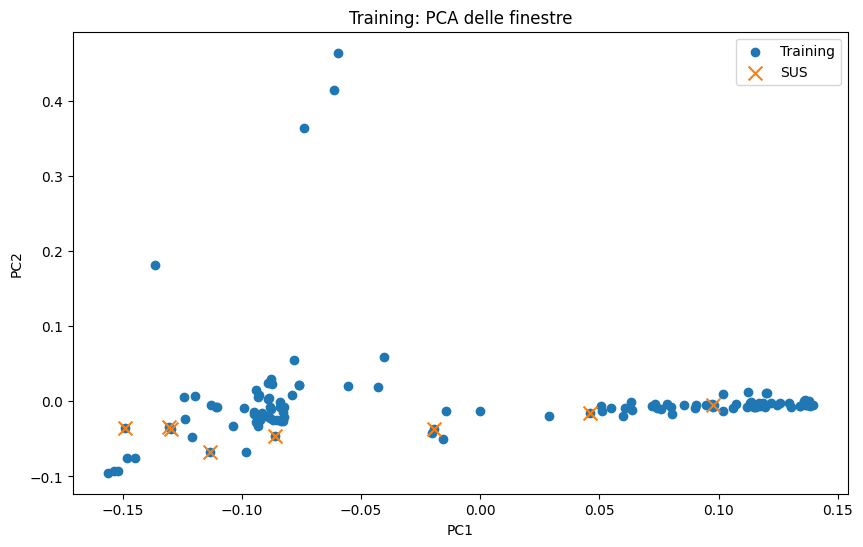

In [ ]:
plt.figure(figsize=(10, 6))

# Tutte le finestre
plt.scatter(
    X_train_pca[:, 0],
    X_train_pca[:, 1],
    label="Training"
)

# Finestre SUS
sus_windows = y_train["sus_window"].values == 1

plt.scatter(
    X_train_pca[sus_windows, 0],
    X_train_pca[sus_windows, 1],
    marker="x",
    s=100,
    label="SUS"
)

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Training: PCA delle finestre")
plt.legend()
plt.show()

Il risultato è:

PC1 → 53,52%

PC2 → 25,86%

Significa che la prima componente principale, PC1, riesce a rappresentare circa il 53,5% della variabilità presente nei dati.

La seconda, PC2, rappresenta circa il 25,9%.

Insieme:

53,52% + 25,86% = 79,38%

Quindi le due dimensioni che abbiamo usato nel grafico rappresentano circa il 79,4% della variabilità complessiva delle 32 feature.

Guardando il grafico, si vede che le finestre non sono distribuite uniformemente.

Ci sono diversi gruppi/zone, per esempio una concentrazione molto evidente verso destra e altre concentrazioni a sinistra.

Le X arancioni sono le finestre SUS.

La cosa interessante è che le SUS non sembrano tutte formare un unico gruppo separato.

La varianza spiegata indica quanta della variabilità presente nelle nostre 32 feature viene conservata dalle componenti PCA che stiamo visualizzando.


PC1 + PC2 conservano circa il 79,4% della variabilità delle finestre del training.

E questo rende il grafico abbastanza utile per avere una prima idea della struttura dei dati.

In [ ]:
print(y_train.columns)
print(y_validation.columns)
print(y_test.columns)


Index(['n_events', 'sus', 'evil', 'sus_window', 'evil_window'], dtype='object')
Index(['n_events', 'sus', 'evil', 'sus_window', 'evil_window'], dtype='object')
Index(['n_events', 'sus', 'evil', 'sus_window', 'evil_window'], dtype='object')


beth.ipynb → preparazione dati

beth_models.ipynb → modelli e risultati

e un file .pkl come ponte tra i due.

In [ ]:
import pickle
from google.colab import drive

drive.mount('/content/drive')

dati_preparati = {
    "X_train": X_train,
    "X_validation": X_validation,
    "X_test": X_test,
    "X_train_rel": X_train_rel,
    "X_validation_rel": X_validation_rel,
    "X_test_rel": X_test_rel,
    "y_train": y_train,
    "y_validation": y_validation,
    "y_test": y_test,
    "event_features": event_features
}

with open("/content/drive/MyDrive/Colab Notebooks/beth_prepared.pkl", "wb") as f:
    pickle.dump(dati_preparati, f)

print("Dati preparati salvati su Google Drive.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dati preparati salvati su Google Drive.
